## [LAB-07] 추론통계

### 06-2_교차분석 모듈화

### #01 준비작업

#### 1. 라이브러리 참조

In [4]:
from jussam import load_data
from helpers import *

#### 2. 데이터셋 불러오기

In [5]:
origin = load_data('movie_view')
origin.head()

📚 OTT 서비스 업체 무비뷰의 회원 500명을 대상으로 조사된 가상의 데이터 셋

    field         description
--  ------------  --------------------------------------
 0  회원ID        회원 식별자 (인덱스)
 1  가입요일      가입한 요일(월~일)
 2  성별          남성 / 여성
 3  프리미엄전환  프리미엄 요금제 전환 여부(전환/미전환)
 4  지역          서울 / 부산 / 대구
 5  선호장르      액션 / 로맨스 / 다큐 / 예능
 6  베타그룹      신규 UI 베타테스트 그룹(A/B)
 7  베타만족      베타테스트 만족 여부(만족/불만족)



,가입요일,성별,지역,선호장르,프리미엄전환,베타그룹,베타만족
회원ID,,,,,,,
M0001,토,여성,부산,다큐,미전환,NaN,NaN
M0002,토,남성,서울,예능,미전환,NaN,NaN
M0003,금,여성,대구,다큐,미전환,NaN,NaN
M0004,토,남성,서울,로맨스,미전환,NaN,NaN
M0005,일,남성,대구,다큐,미전환,NaN,NaN


### #02 모듈화 기능 확인

#### 1. 적합도 검정 함수

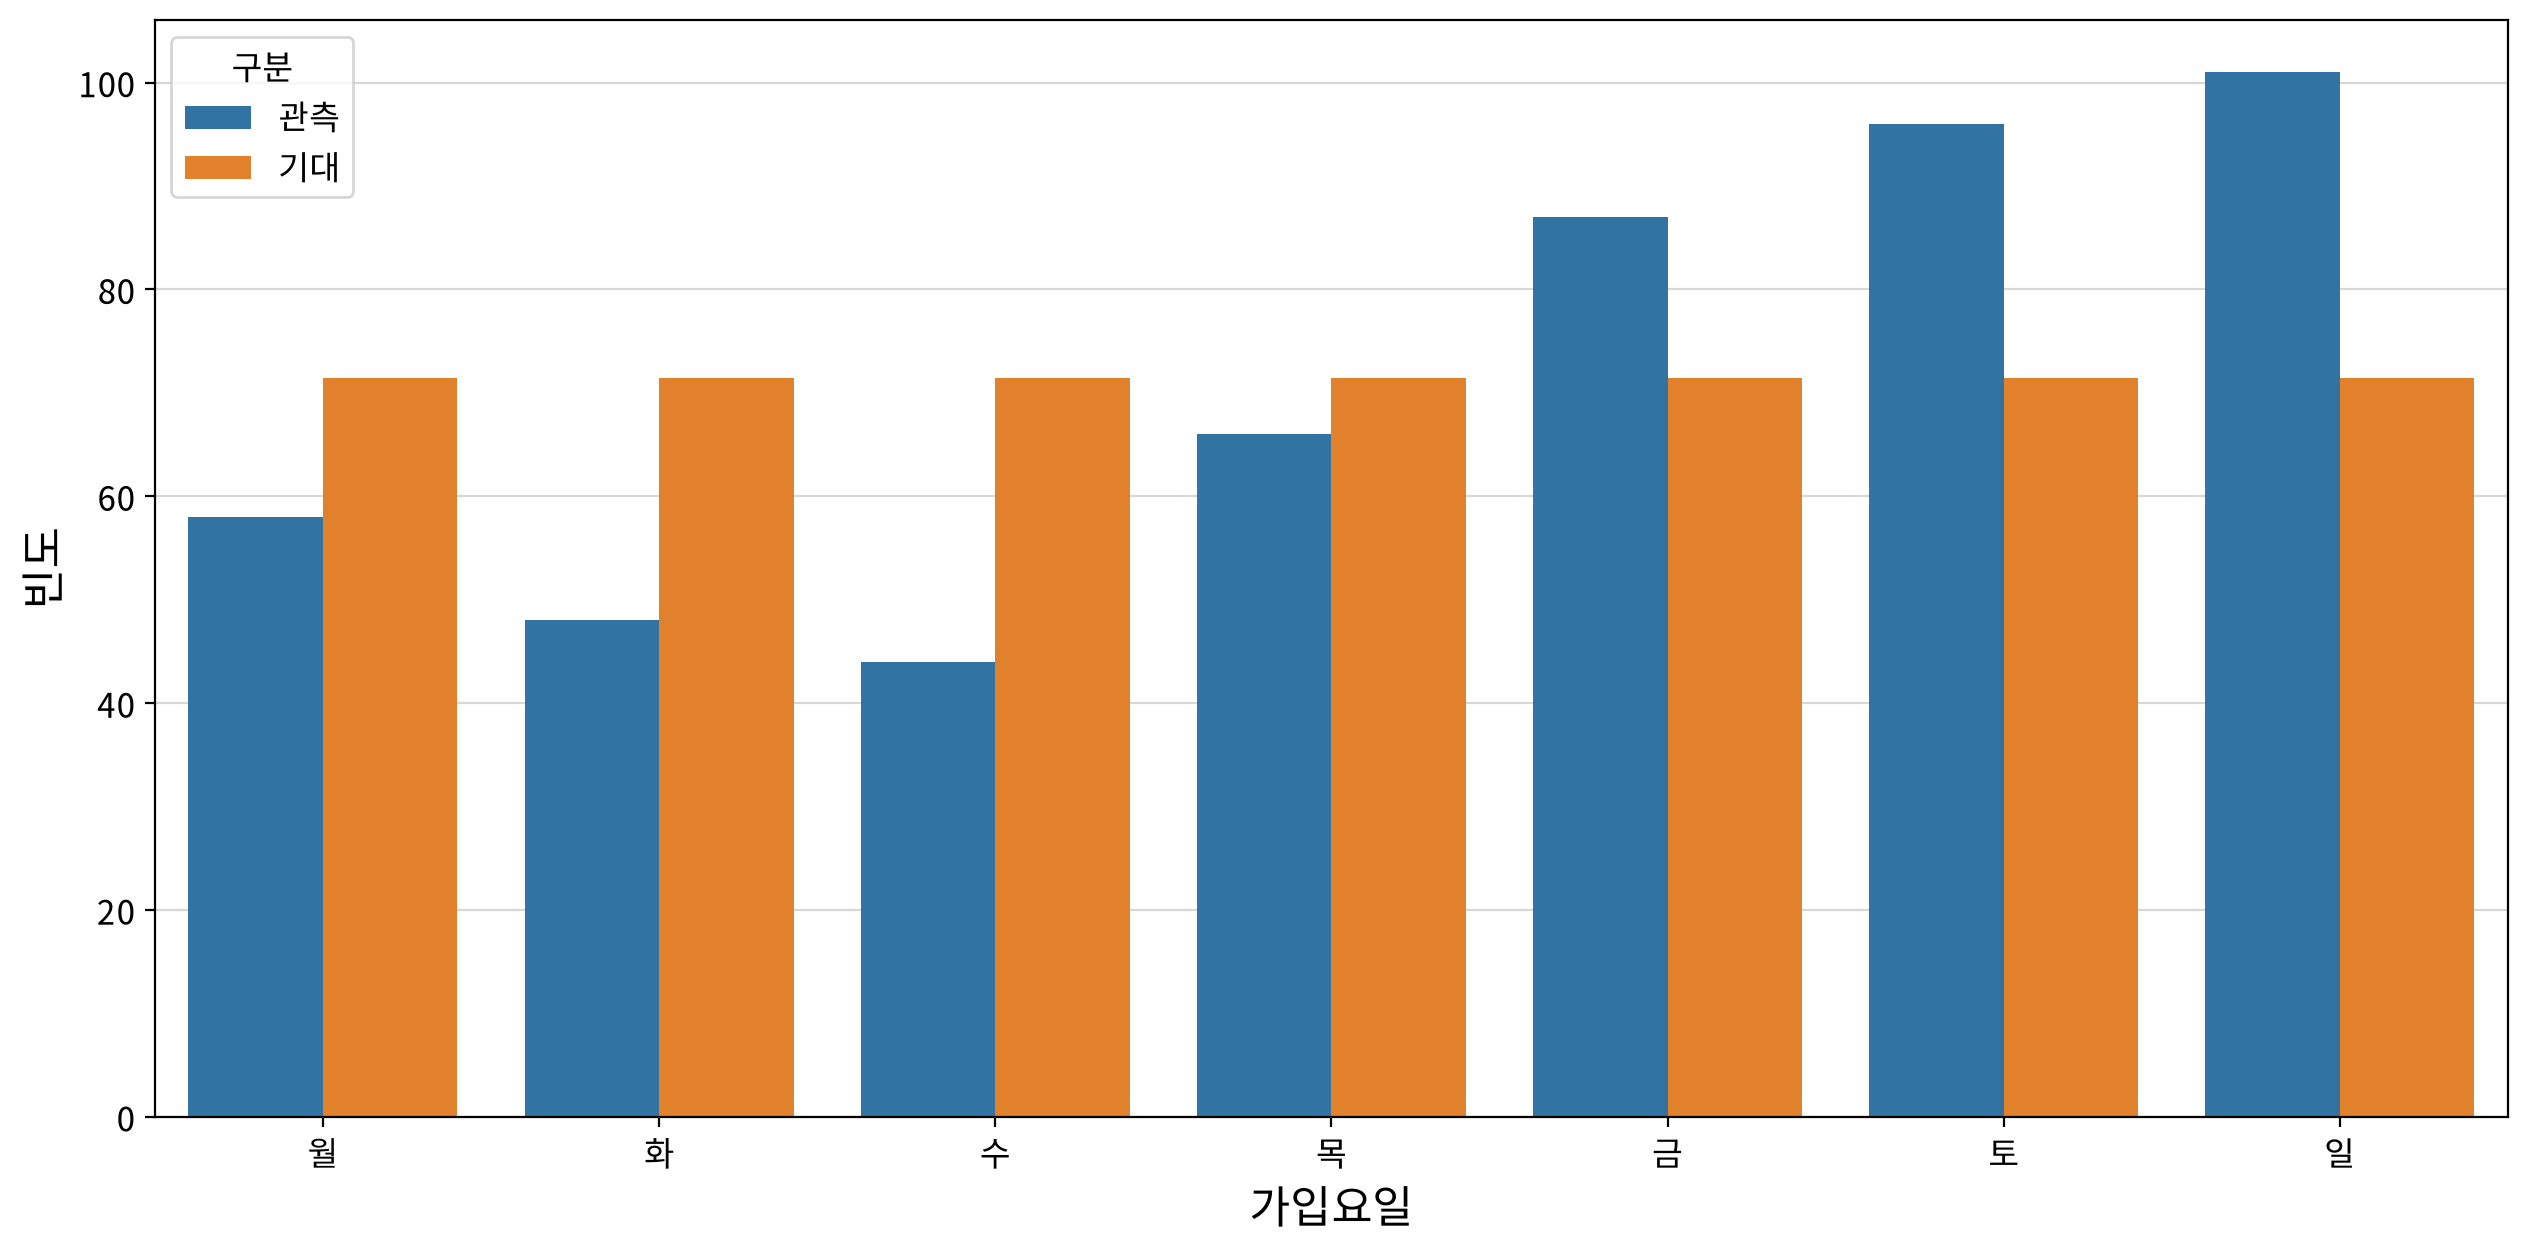

,chi2,dof,p-value,significant,effect(w),strength,min_expected,assumption
Chi-square goodness-of-fit,45.244,6,0.000,True,0.301,Moderate,71.430,True


In [6]:
my_stats.chi2_goodness_of_fit(origin, '가입요일',
            order=['월', '화', '수', '목', '금', '토', '일'])

#### 2. 독립성 검정 함수 확인

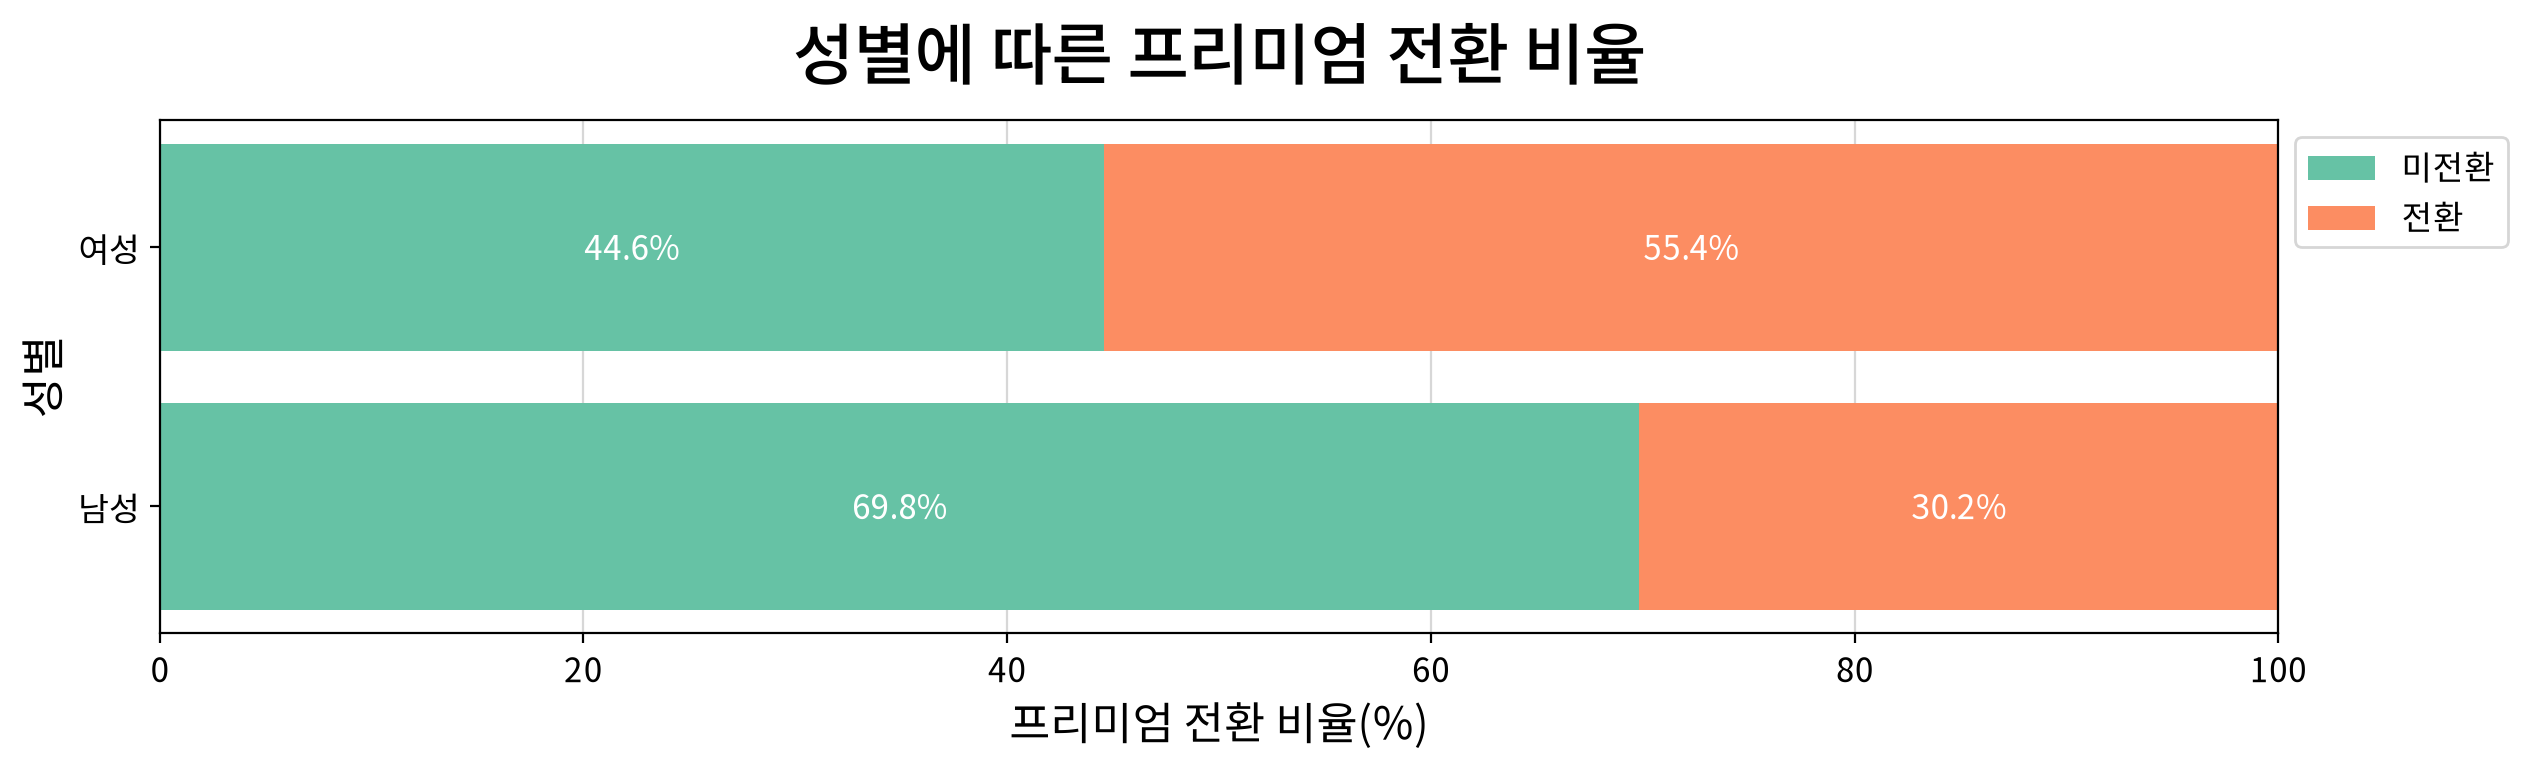

,,test,chi2,dof,p-value,significant,effect(V),strength,min_expected,assumption
row,col,,,,,,,,,
성별,프리미엄전환,Chi-square test of independence,31.453,1,0.000,True,0.251,Weak,104.540,True


In [7]:
my_stats.chi2_independence(origin, '성별', '프리미엄전환',
                           orient='h', palette='Set2',
                           title="성별에 따른 프리미엄 전환 비율",
                           xlabel="프리미엄 전환 비율(%)", ylabel="성별", height=400)

#### 3. 동질성 검정 함수 확인

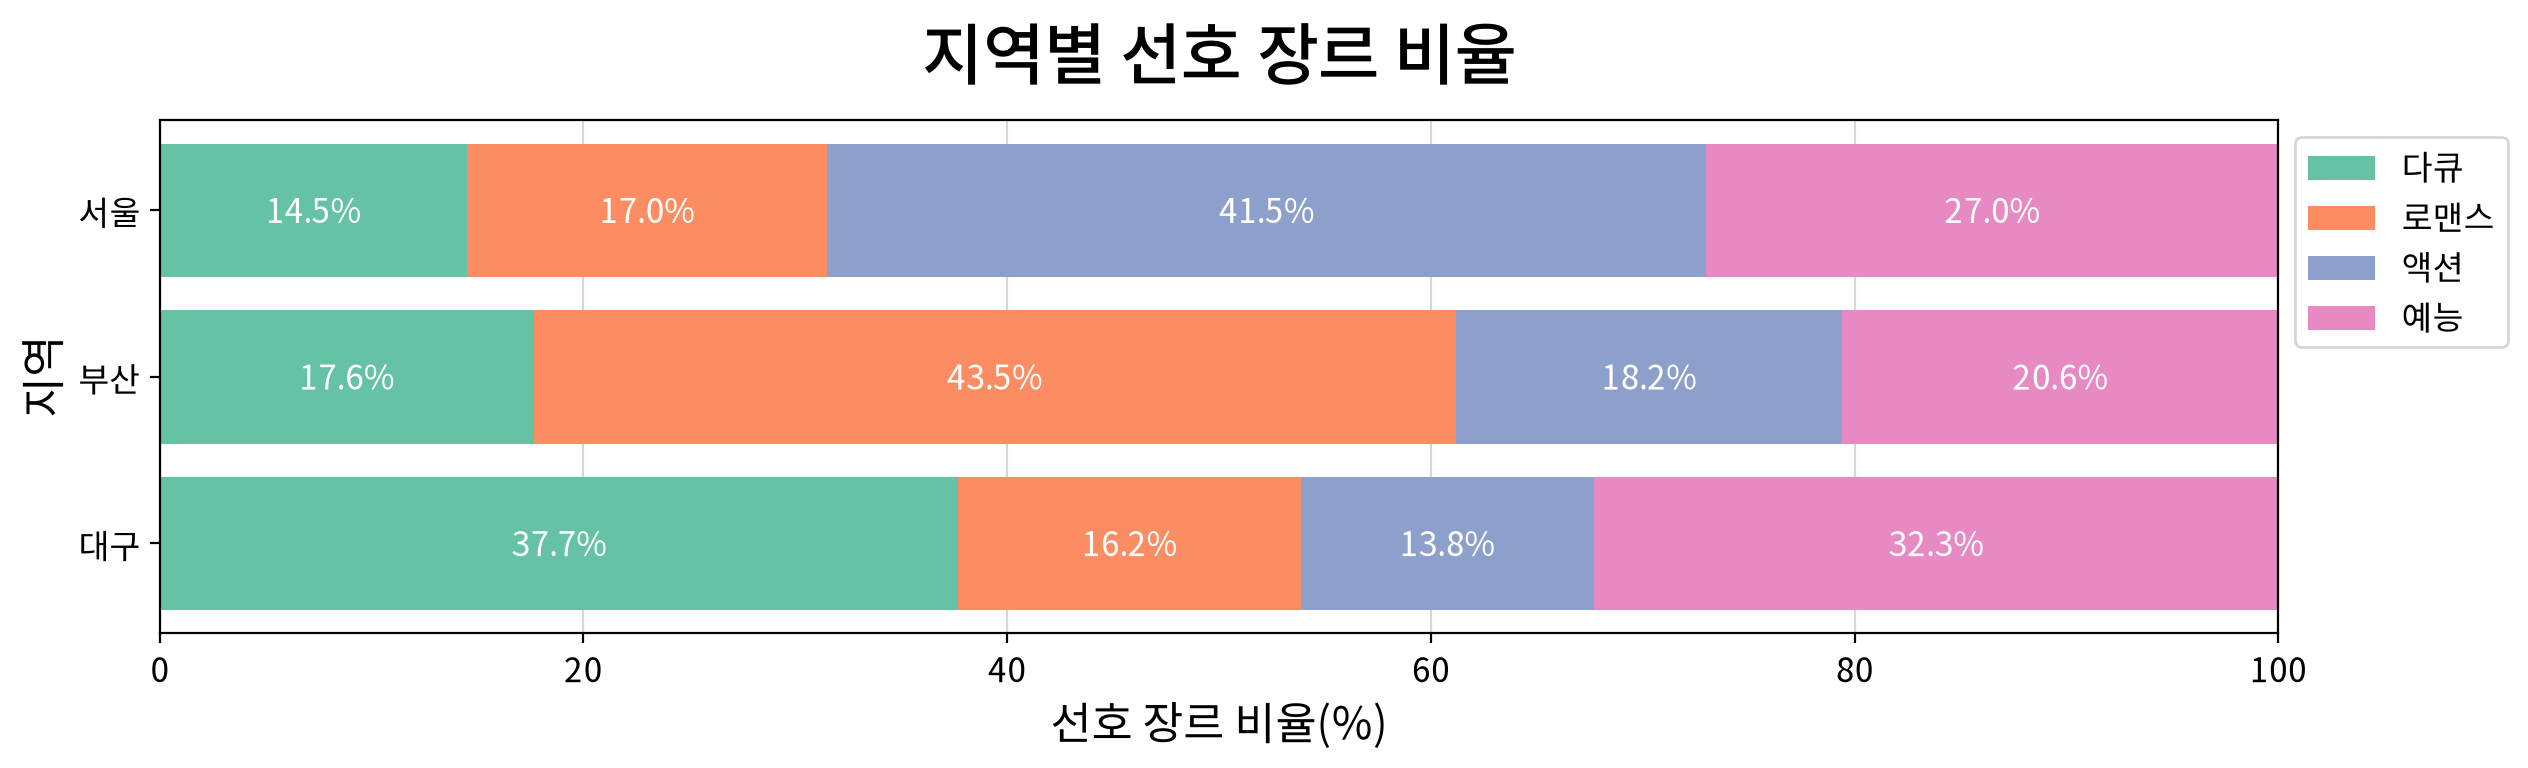

,,test,chi2,dof,p-value,significant,effect(V),strength,min_expected,assumption
row,col,,,,,,,,,
지역,선호장르,Chi-square test of homogeneity,86.156,6,0.000,True,0.293,Weak,28.080,True


In [8]:
my_stats.chi2_homogeneity(origin, '지역', '선호장르',
                          orient='h', palette='Set2', title="지역별 선호 장르 비율",
                          xlabel="선호 장르 비율(%)", ylabel="지역", height=400)

---

## 연습문제

- 당신은 노동연구소에 갓 입사한 신입 데이터 분석가 입니다.
    - 출근 첫 주, 팀장님이 미국 Mid-Atlantic 지역 남성 근로자 3,000명의 임금 실태조사 데이터셋(wage)을 건네며 말합니다.
    - 아래 6개의 미션을 **스스로 코드를 작성해** 해결하고, 각 문제의 답을 도출하세요.

> 올해 보고서 주제는 **'어떤 사람이, 어떤 일터에서, 어떤 보호를 받고 일하는가'** 예요.   
> 숫자(임금)는 회귀팀이 맡고, 당신은 **'범주와 범주 사이의 관계'** 를 책임지세요.   
> 교차표를 만들고 카이제곱 검정을 돌려서, **결론을 한 단어로** 가져오세요.   
> 데이터를 불러온 후 아래의 코드를 실행하면 데이터셋이 좀 더 깔끔해 질거예요.

        df = origin.copy()   
        for c in ['maritl', 'race', 'education', 'region', 'jobclass', 'health', 'health_ins']:   
            df[c] = df[c].str.replace(r'^\d+\.\s*', '', regex=True)   

        df.head()

In [9]:
# 데이터 불러오기
origin = load_data('wage')
origin.head()

📚 경제 및 노동 시장에 관련된 정보를 담고 있는 데이터셋(출처: ADsP 기출문제)

    field       description
--  ----------  ------------------
 0  year        년도
 1  age         나이
 2  maritl      결혼여부
 3  race        근로자의 인종
 4  education   교육수준
 5  region      지역
 6  jobclass    직군
 7  health      건상상태
 8  health_ins  건강보험 가입 여부
 9  logwage     임금(로그값)
10  wage        임금



,year,age,maritl,race,education,region,jobclass,health,health_ins,logwage,wage
0,2006,18,1. Never Married,1. White,1. < HS Grad,2. Middle Atlantic,1. Industrial,1. <=Good,2. No,4.318,75.043
1,2004,24,1. Never Married,1. White,4. College Grad,2. Middle Atlantic,2. Information,2. >=Very Good,2. No,4.255,70.476
2,2003,45,2. Married,1. White,3. Some College,2. Middle Atlantic,1. Industrial,1. <=Good,1. Yes,4.875,130.982
3,2003,43,2. Married,3. Asian,4. College Grad,2. Middle Atlantic,2. Information,2. >=Very Good,1. Yes,5.041,154.685
4,2005,50,4. Divorced,1. White,2. HS Grad,2. Middle Atlantic,2. Information,1. <=Good,1. Yes,4.318,75.043


In [10]:
# 데이터셋을 깔끔하게
df = origin.copy()   
for c in ['maritl', 'race', 'education', 'region', 'jobclass', 'health', 'health_ins']:
    df[c] = df[c].str.replace(r'^\d+\.\s*', '', regex=True)   

df.head()

,year,age,maritl,race,education,region,jobclass,health,health_ins,logwage,wage
0,2006,18,Never Married,White,< HS Grad,Middle Atlantic,Industrial,<=Good,No,4.318,75.043
1,2004,24,Never Married,White,College Grad,Middle Atlantic,Information,>=Very Good,No,4.255,70.476
2,2003,45,Married,White,Some College,Middle Atlantic,Industrial,<=Good,Yes,4.875,130.982
3,2003,43,Married,Asian,College Grad,Middle Atlantic,Information,>=Very Good,Yes,5.041,154.685
4,2005,50,Divorced,White,HS Grad,Middle Atlantic,Information,<=Good,Yes,4.318,75.043


### 문제 1 - "절반씩 일하나요?"
- 팀장님이 묻습니다.<br>"우리 표본의 근로자가 Industrial 직군과 Information 직군에 정확히 절반씩(50:50) 나뉘어 있다고 봐도 될까요?"
    - 유의수준 5%에서, "두 직군이 균등하게 분포한다"는 귀무가설에 대한 판정은? (채택 / 기각)

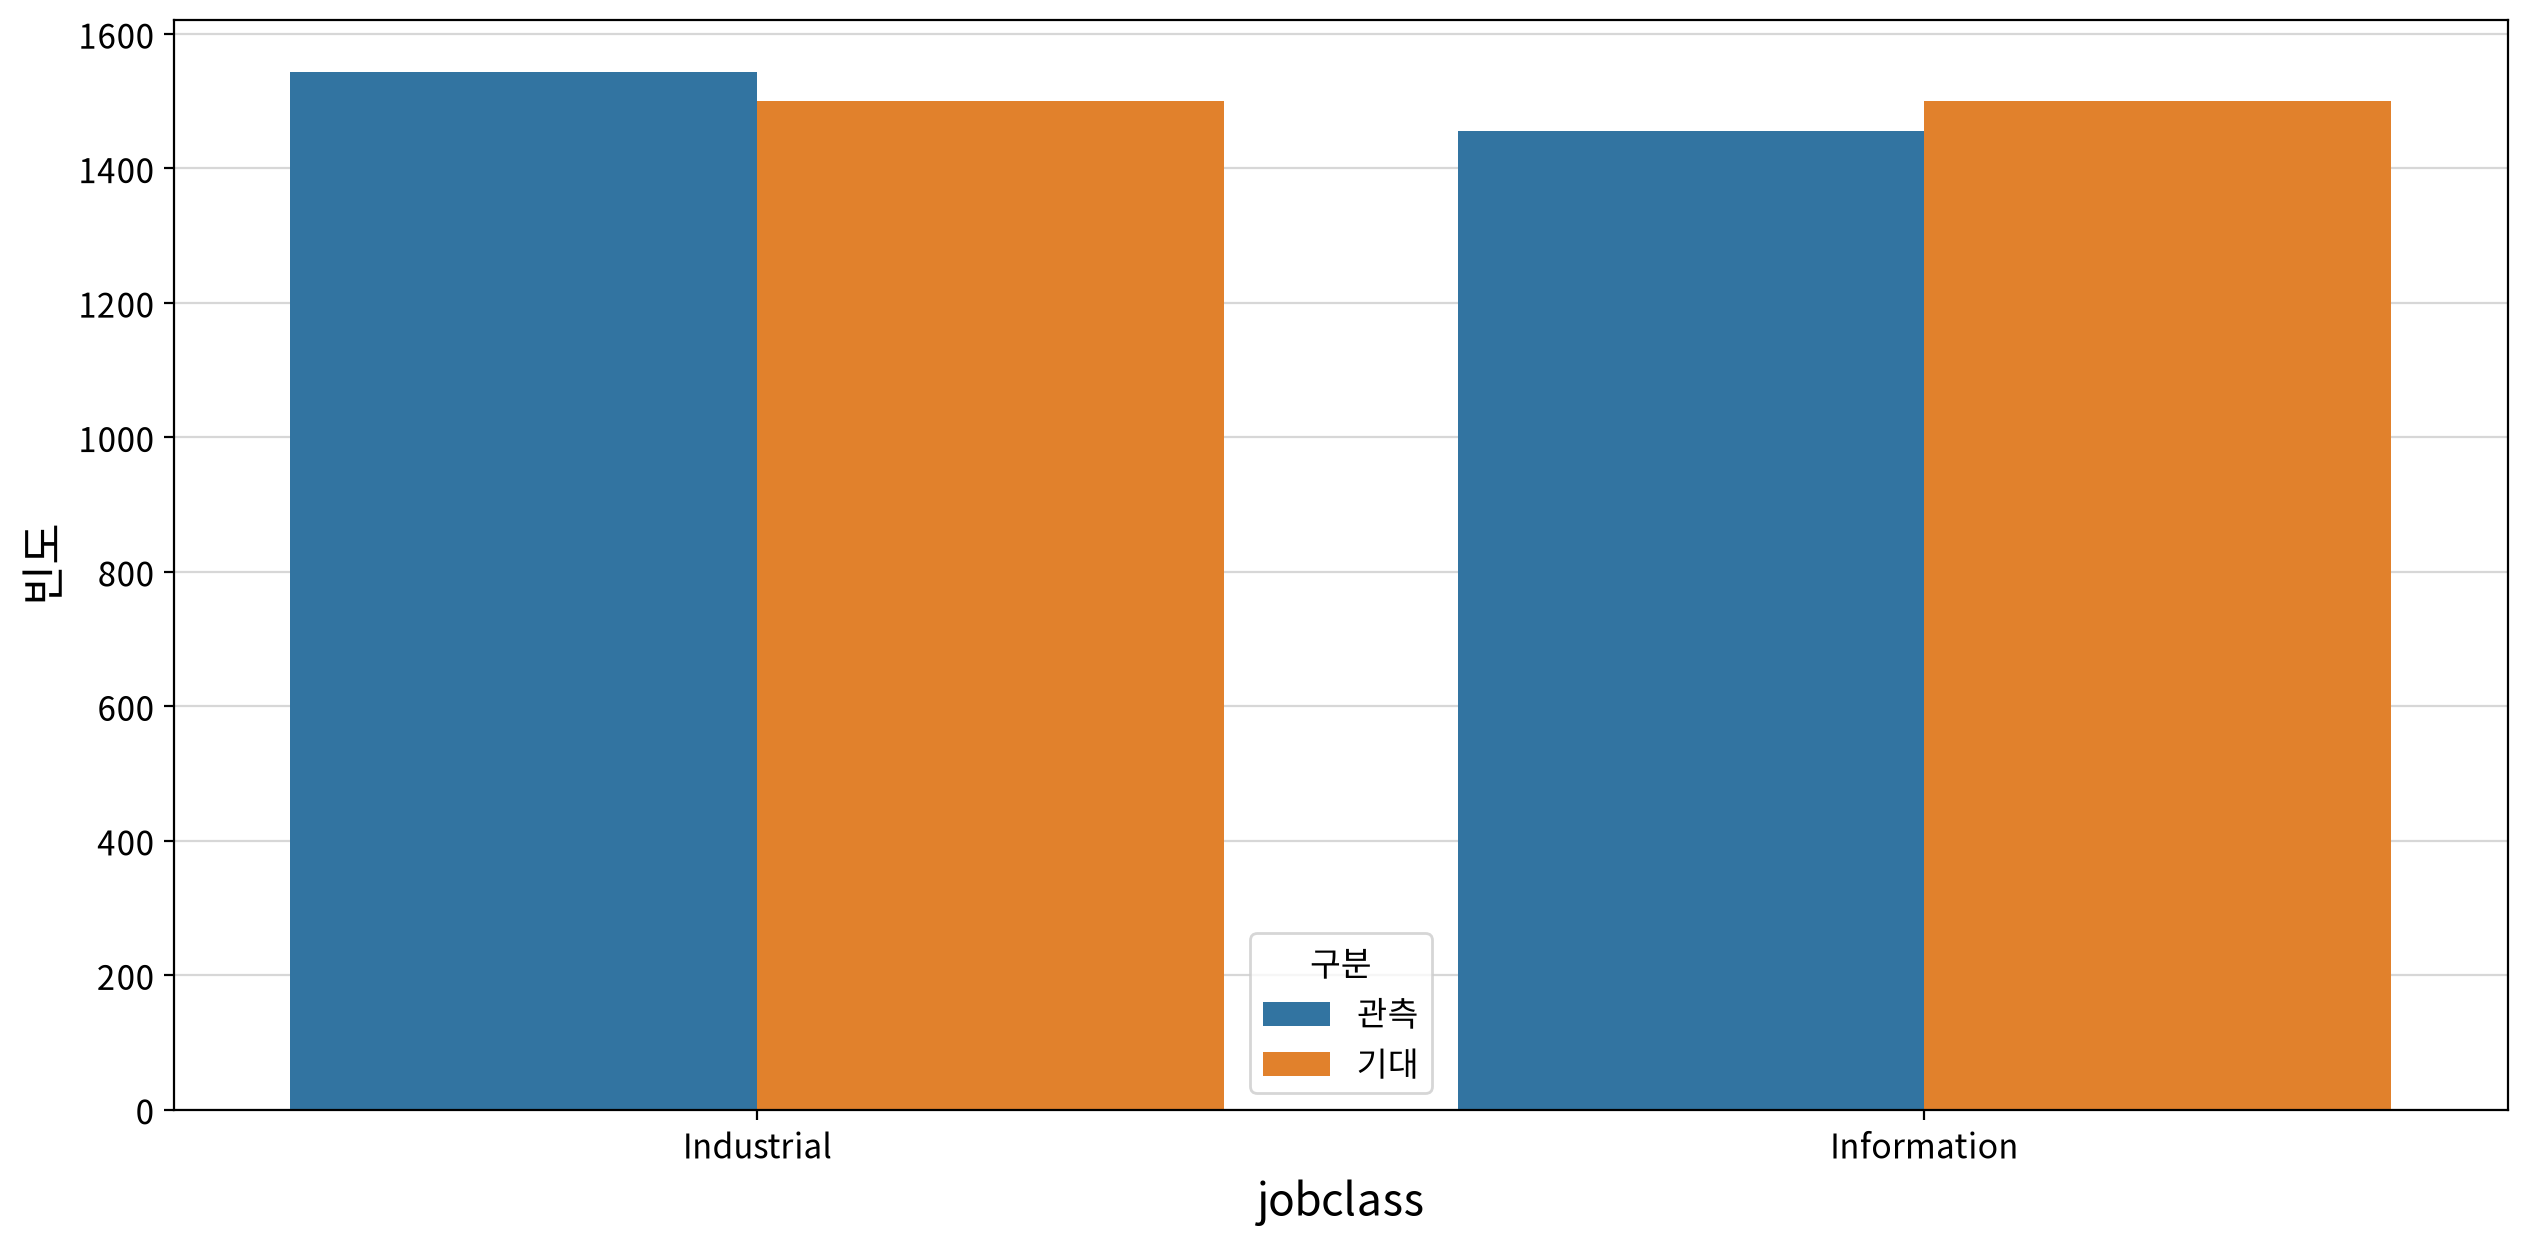

,chi2,dof,p-value,significant,effect(w),strength,min_expected,assumption
Chi-square goodness-of-fit,2.581,1,0.108,False,0.029,Negliglible,1500.000,True


In [11]:
my_stats.chi2_goodness_of_fit(df, 'jobclass')

> 귀무가설을 기각할 수 없음, 즉 두 직군은 균등하게 분포함

### 문제 2 - "배움이 일터를 바꾸나요?"
"교육을 더 받은 사람일수록 사무·정보(Information) 직군에서 일할까요, 아니면 교육수준과 직군은 서로 무관할까요?"

In [12]:
# 라이브러리 참조
from pandas import Categorical

# 교육수준을 카테고리로 변경
df1 = my_qtcheck.set_type(df, as_category=["education"])
df1['education'] = df1['education'].cat.reorder_categories(new_categories = ["< HS Grad", "HS Grad", "Some College", "College Grad", "Advanced Degree"], ordered=True)
df1['education'].cat.categories

<class 'pandas.DataFrame'>
RangeIndex: 3000 entries, 0 to 2999
Data columns (total 11 columns):
 #   Column      Non-Null Count  Dtype   
---  ------      --------------  -----   
 0   year        3000 non-null   int64   
 1   age         3000 non-null   int64   
 2   maritl      3000 non-null   str     
 3   race        3000 non-null   str     
 4   education   3000 non-null   category
 5   region      3000 non-null   str     
 6   jobclass    3000 non-null   str     
 7   health      3000 non-null   str     
 8   health_ins  3000 non-null   str     
 9   logwage     3000 non-null   float64 
 10  wage        3000 non-null   float64 
dtypes: category(1), float64(2), int64(2), str(6)
memory usage: 389.6 KB


Index(['< HS Grad', 'HS Grad', 'Some College', 'College Grad',
       'Advanced Degree'],
      dtype='str')

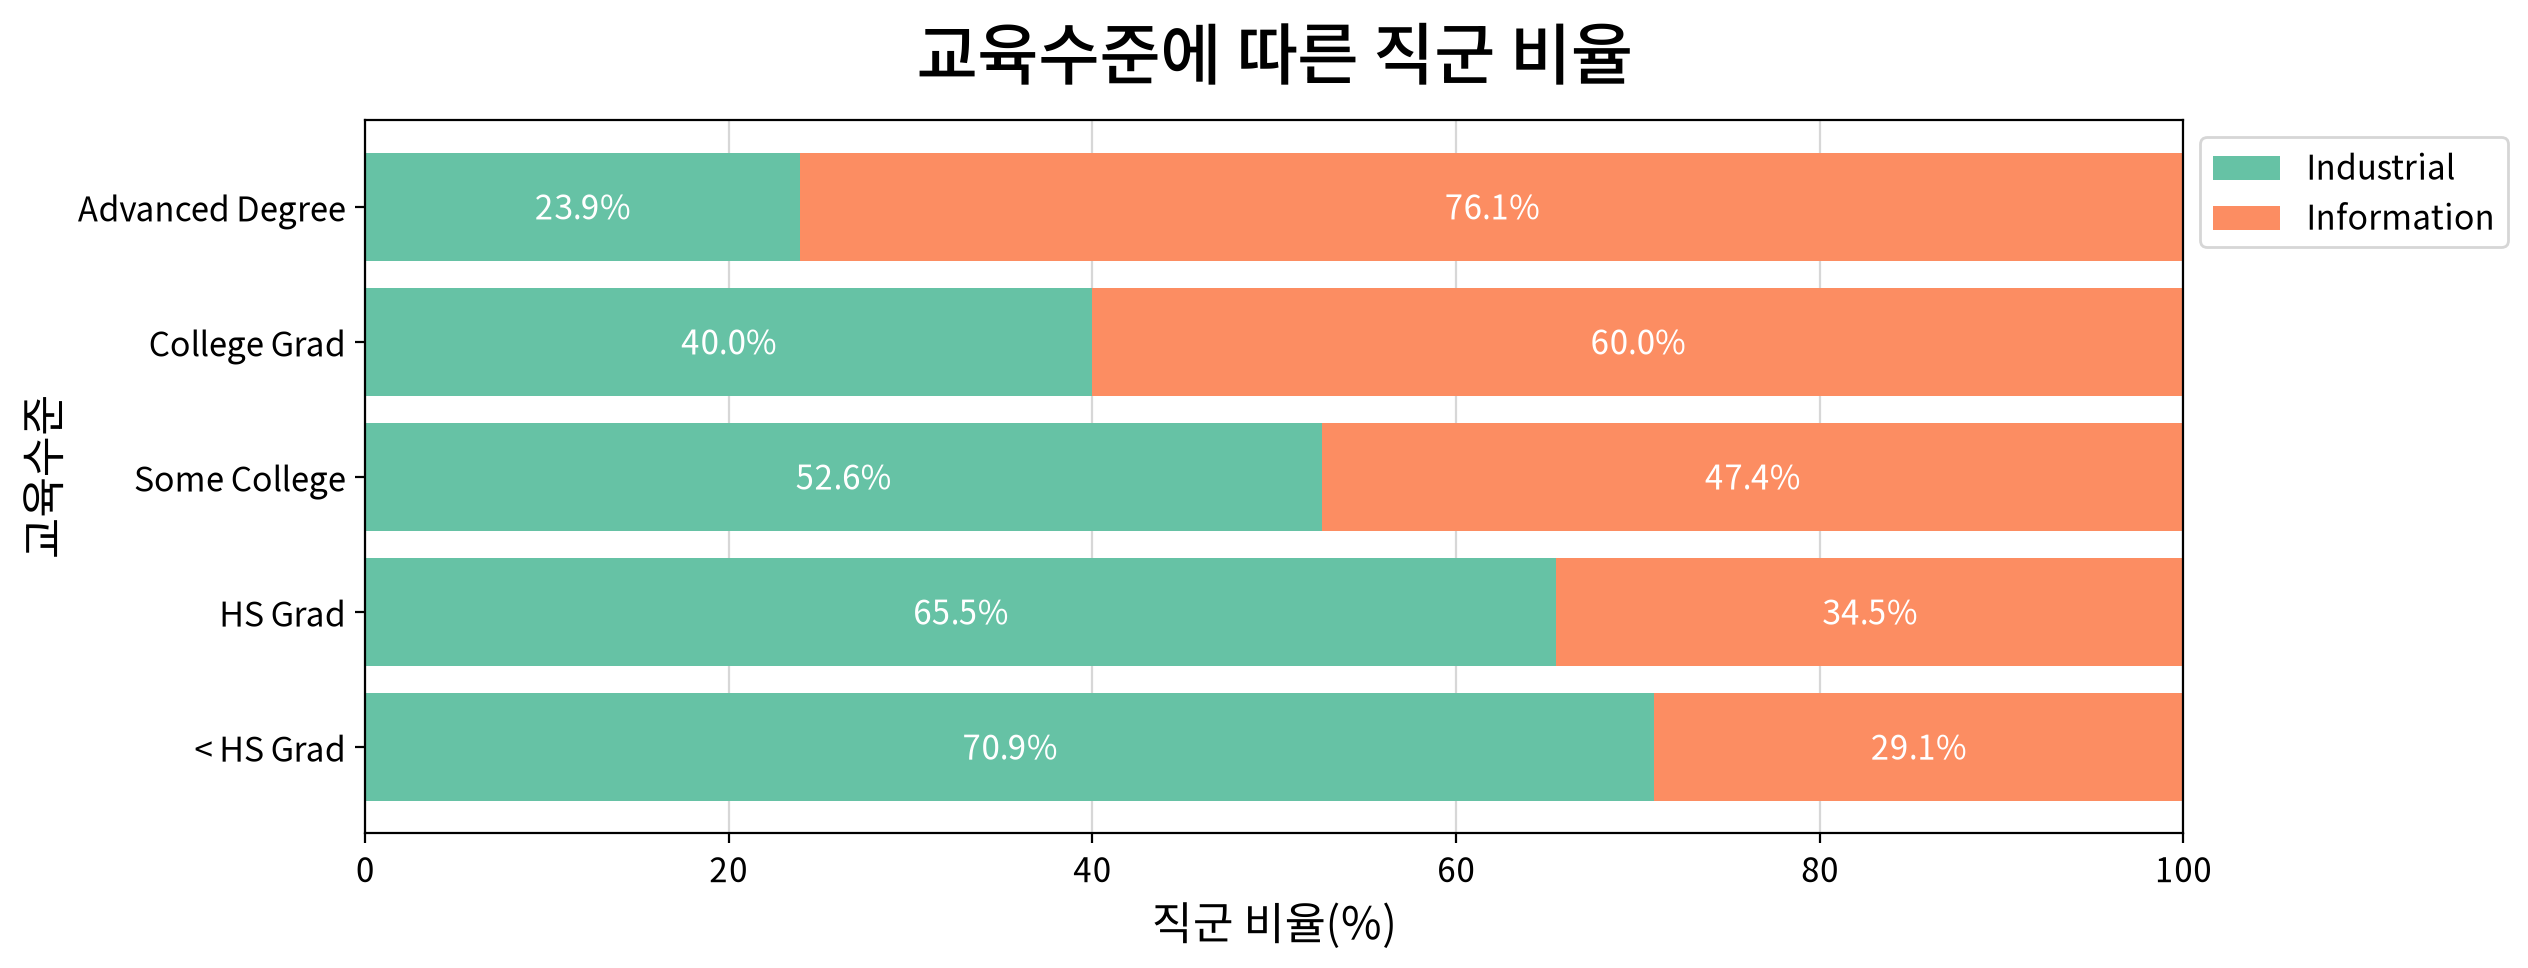

,,test,chi2,dof,p-value,significant,effect(V),strength,min_expected,assumption
row,col,,,,,,,,,
education,jobclass,Chi-square test of independence,282.643,4,0.000,True,0.307,Moderate,130.070,True


In [13]:
my_stats.chi2_independence(df1, 'education', 'jobclass',
                           orient='h', palette='Set2',
                           title="교육수준에 따른 직군 비율",
                           xlabel="직군 비율(%)", ylabel="교육수준", height=500)

> `교육수준과 직군은 독립적이다`라는 귀무가설을 기각, 즉 교육수준과 직군은 상관이 있음   
> 또한, 그래프를 통해 교육수준이 높아질 수록 Information 직군의 비율이 높아진다는 것을 확인할 수 있음

### 문제 3 - "누가 사각지대에 있나요?"
복지팀의 긴급 요청:   
"건강보험 미가입자를 줄이는 캠페인을 하려는데, 가장 우선 지원해야 할 교육수준 집단을 콕 집어주세요."

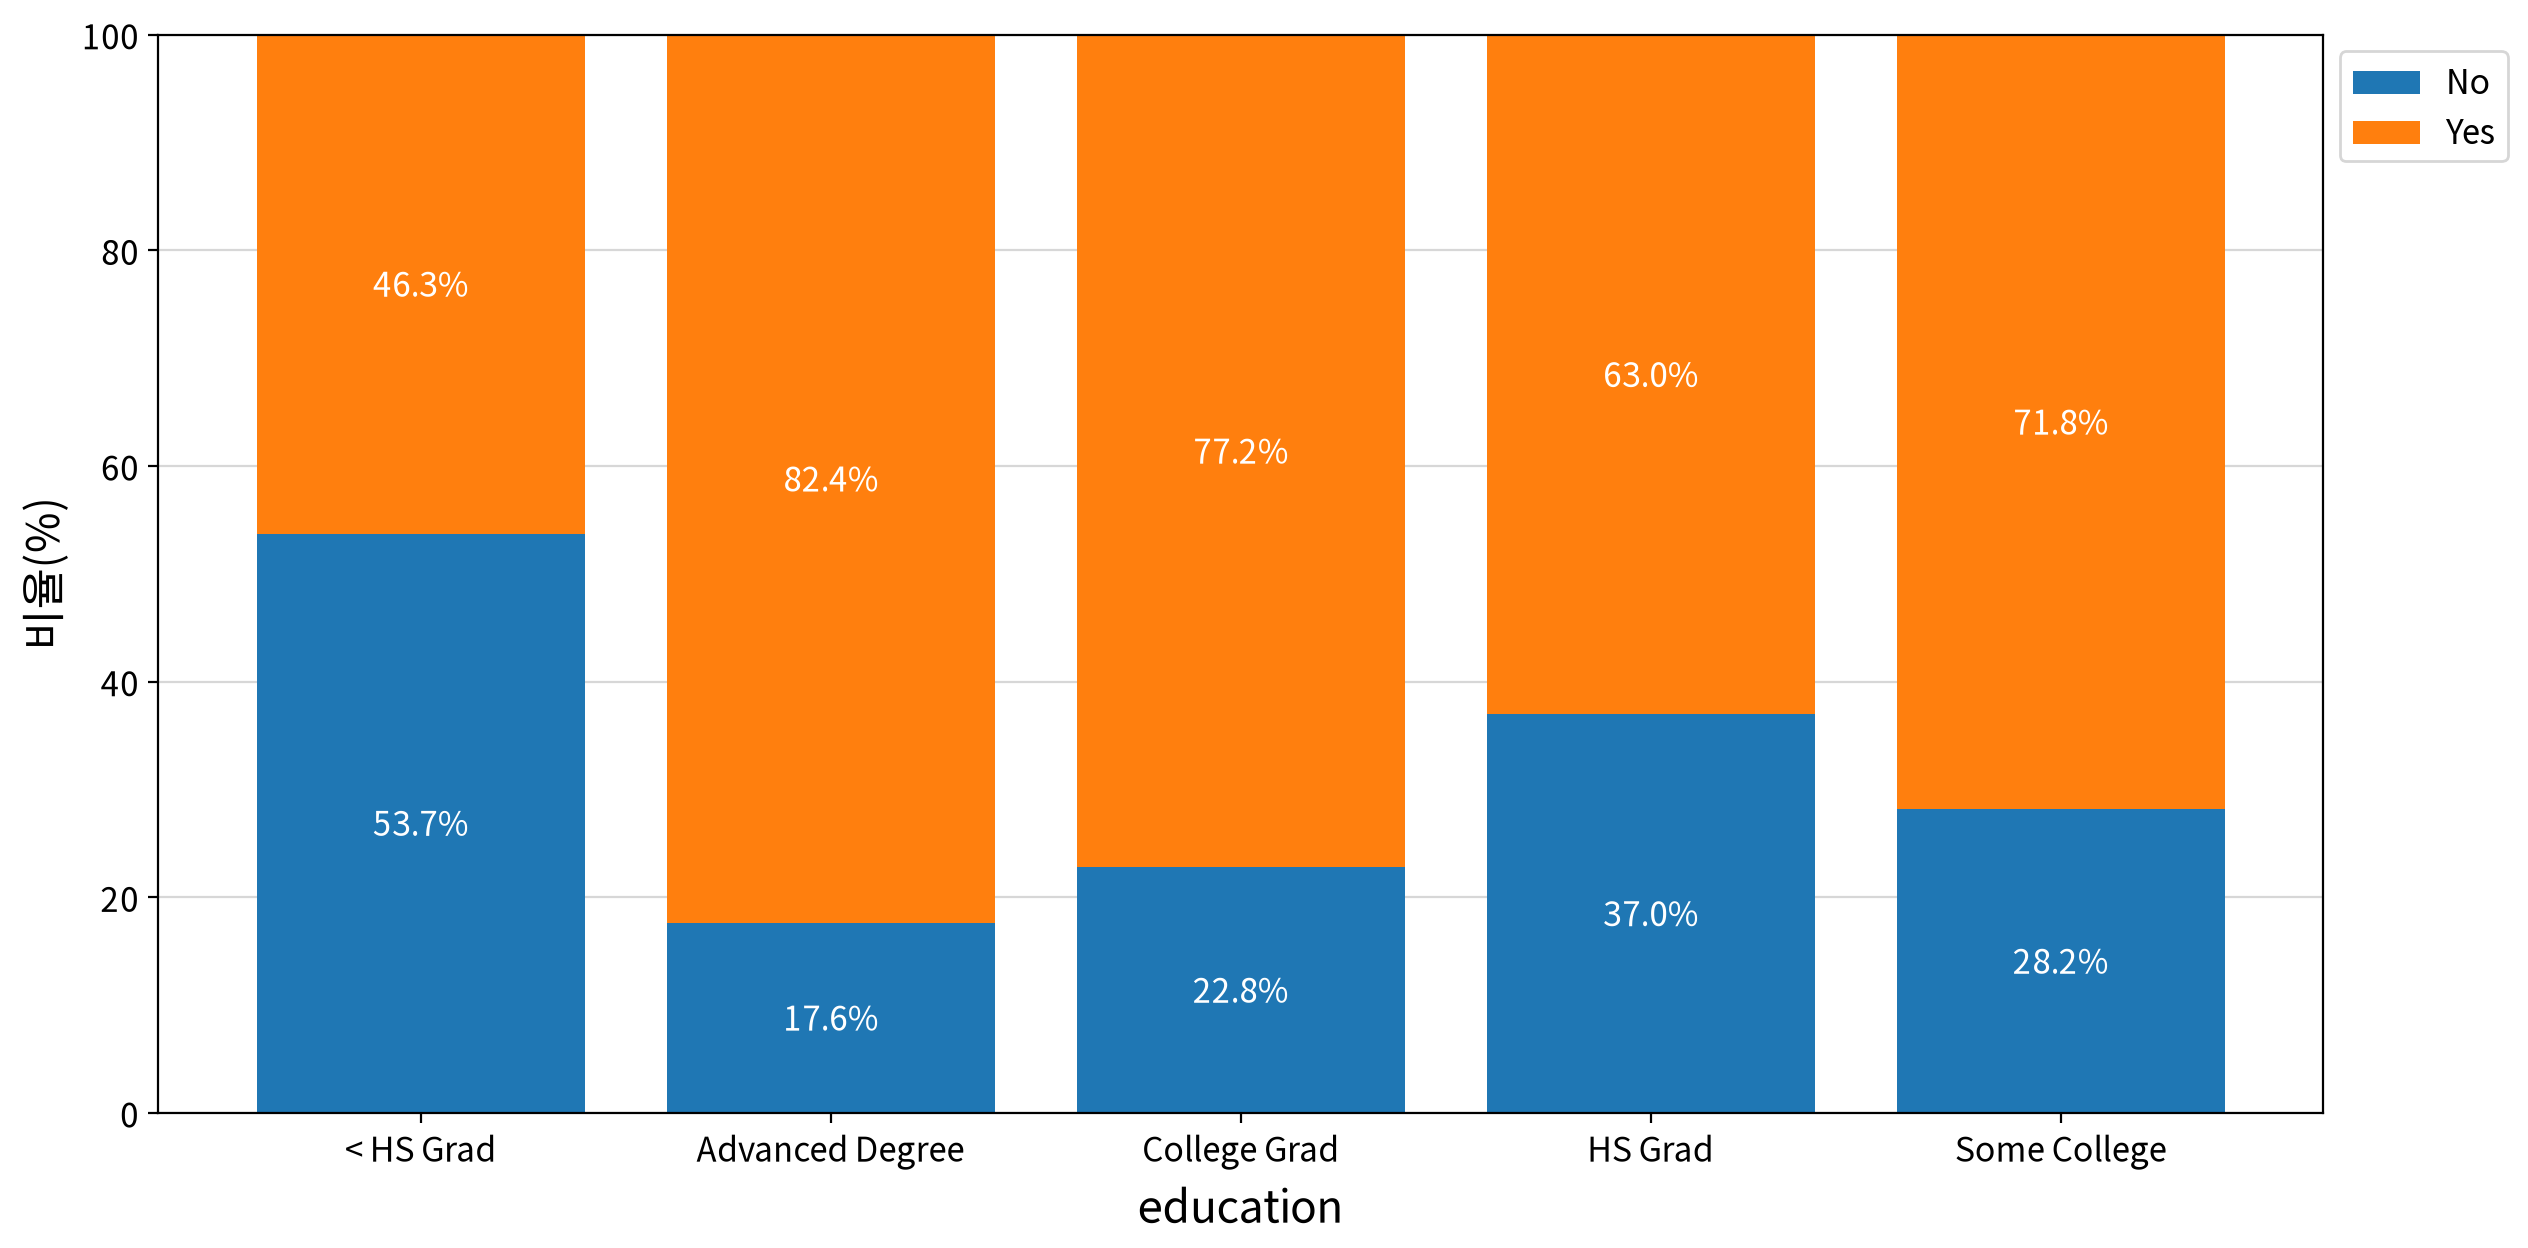

,,test,chi2,dof,p-value,significant,effect(V),strength,min_expected,assumption
row,col,,,,,,,,,
education,health_ins,Chi-square test of independence,141.635,4,0.000,True,0.217,Weak,81.920,True


In [21]:
my_stats.chi2_independence(df, 'education', 'health_ins')

> 보험 미가입자의 비중이 가장 큰 `< HS Grad` 집단을 상대로 해야 함

### 문제 4 - "어떤 일터가 더 안전망이 두텁나요?"
"Industrial 직군과 Information 직군, 두 집단의 건강보험 가입 분포가 같은지 비교해 주세요. 다르다면 어느 쪽 가입률이 높죠?"

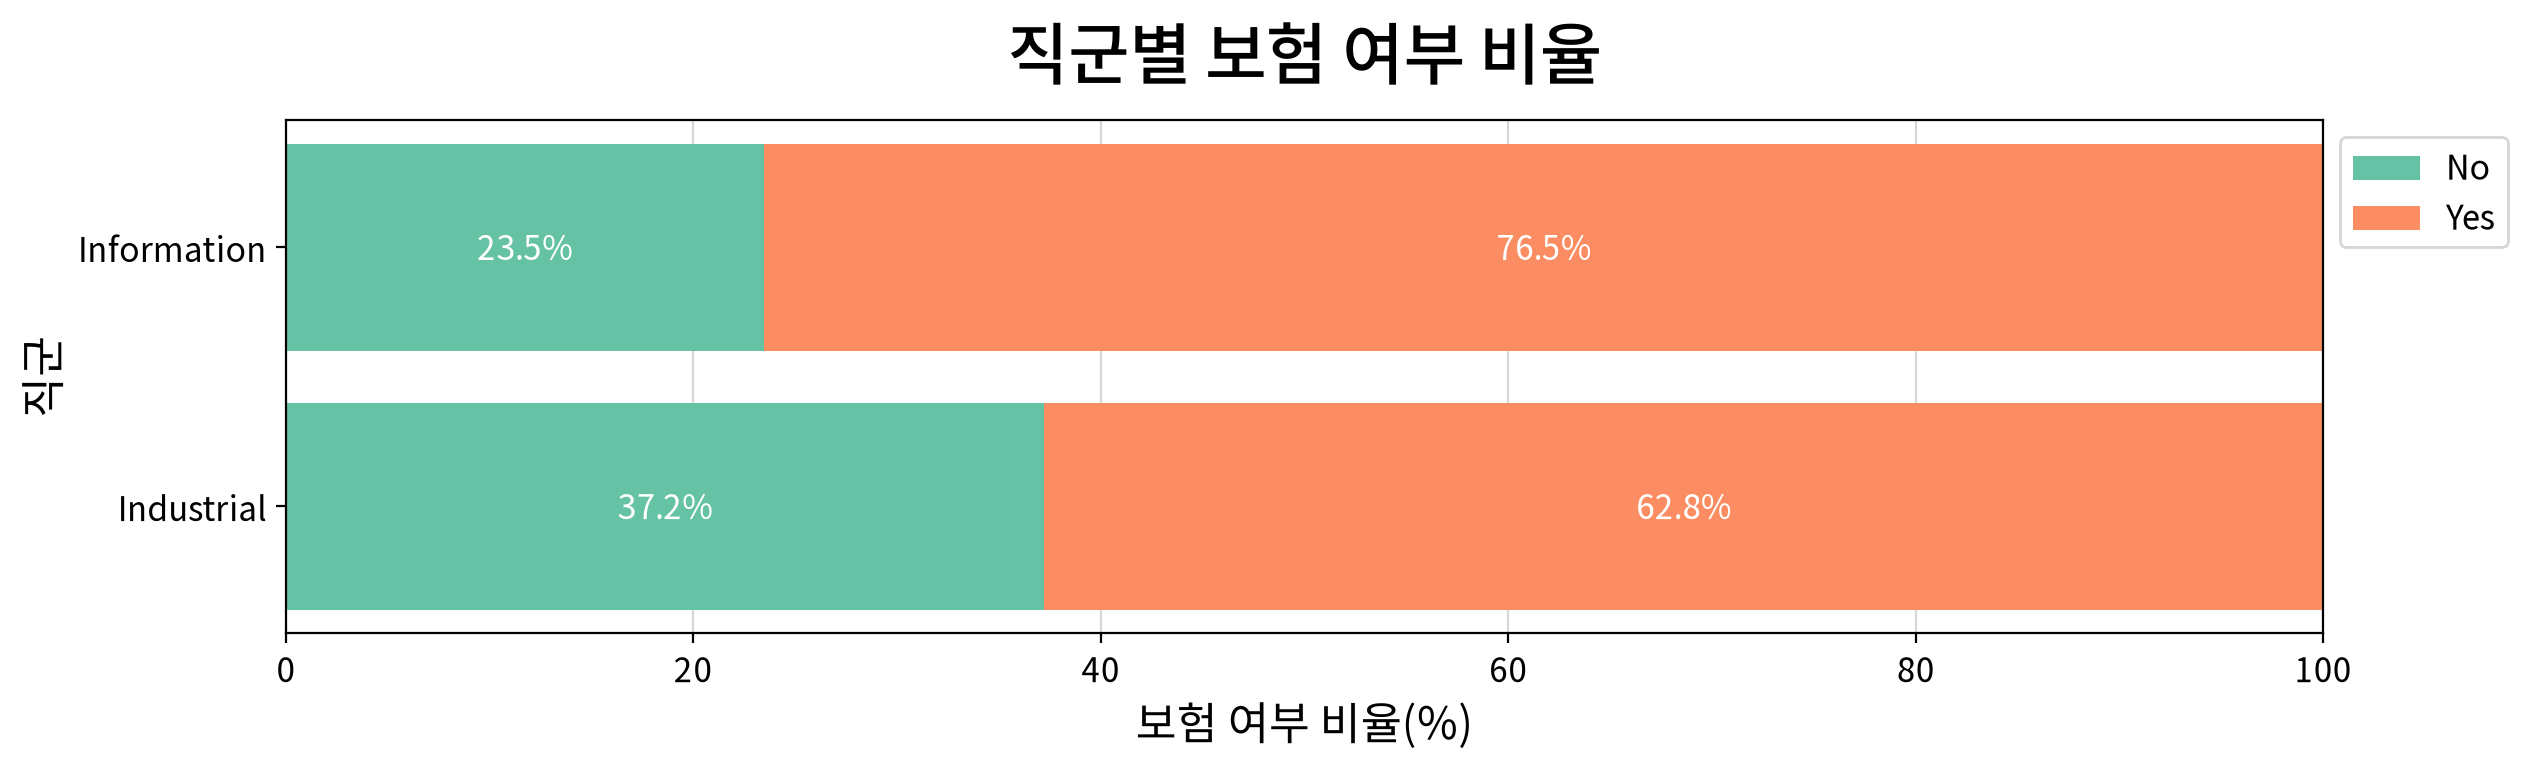

,,test,chi2,dof,p-value,significant,effect(V),strength,min_expected,assumption
row,col,,,,,,,,,
jobclass,health_ins,Chi-square test of homogeneity,66.126,1,0.000,True,0.148,Weak,445.050,True


In [15]:
my_stats.chi2_homogeneity(df1, 'jobclass', 'health_ins',
                          orient='h', palette='Set2', title="직군별 보험 여부 비율",
                          xlabel="보험 여부 비율(%)", ylabel="직군", height=400)

> `두 직군의 건강보험 가입 여부의 분포는 동일하다`라는 귀무가설을 기각, 즉 두 직군의 건강보험 가입 여부의 분포는 같지 않다.   
> 또한, 그래프를 통해 `Information` 직군의 보험가입율이 높은 것을 확인할 수 있음

### 문제 5 - "가장 강한 끈은?"
- "유의하다고 다 같은 게 아니에요.
    - 임금(상위 25%를 '고임금'으로 구분)과 가장 강하게 연결된 범주형 변수가 뭔지 Cramér's V로 비교해 보세요. education, jobclass, health 중에서요."

In [16]:
df1.info()

<class 'pandas.DataFrame'>
RangeIndex: 3000 entries, 0 to 2999
Data columns (total 11 columns):
 #   Column      Non-Null Count  Dtype   
---  ------      --------------  -----   
 0   year        3000 non-null   int64   
 1   age         3000 non-null   int64   
 2   maritl      3000 non-null   str     
 3   race        3000 non-null   str     
 4   education   3000 non-null   category
 5   region      3000 non-null   str     
 6   jobclass    3000 non-null   str     
 7   health      3000 non-null   str     
 8   health_ins  3000 non-null   str     
 9   logwage     3000 non-null   float64 
 10  wage        3000 non-null   float64 
dtypes: category(1), float64(2), int64(2), str(6)
memory usage: 389.7 KB


In [22]:
import numpy as np

# 임금 상위 25%를 '고임금'으로 이진화
df1['고임금'] = np.where(df1['wage'] >= df1['wage'].quantile(0.75), '고임금', '일반')
df1.head()

,year,age,maritl,race,education,region,jobclass,health,health_ins,logwage,wage,wage_group,고임금
0,2006,18,Never Married,White,< HS Grad,Middle Atlantic,Industrial,<=Good,No,4.318,75.043,저임금,일반
1,2004,24,Never Married,White,College Grad,Middle Atlantic,Information,>=Very Good,No,4.255,70.476,저임금,일반
2,2003,45,Married,White,Some College,Middle Atlantic,Industrial,<=Good,Yes,4.875,130.982,고임금,고임금
3,2003,43,Married,Asian,College Grad,Middle Atlantic,Information,>=Very Good,Yes,5.041,154.685,고임금,고임금
4,2005,50,Divorced,White,HS Grad,Middle Atlantic,Information,<=Good,Yes,4.318,75.043,저임금,일반


In [24]:
my_stats.chi2_independence(df1, 'education', '고임금', plot=False)

,,test,chi2,dof,p-value,significant,effect(V),strength,min_expected,assumption
row,col,,,,,,,,,
education,고임금,Chi-square test of independence,567.564,4,0.000,True,0.435,Moderate,69.230,True


In [25]:
my_stats.chi2_independence(df1, 'jobclass', '고임금', plot=False)

,,test,chi2,dof,p-value,significant,effect(V),strength,min_expected,assumption
row,col,,,,,,,,,
jobclass,고임금,Chi-square test of independence,63.346,1,0.000,True,0.145,Weak,376.130,True


In [26]:
my_stats.chi2_independence(df1, 'health', '고임금', plot=False)

,,test,chi2,dof,p-value,significant,effect(V),strength,min_expected,assumption
row,col,,,,,,,,,
health,고임금,Chi-square test of independence,49.404,1,0.000,True,0.128,Weak,221.650,True


> - 교육수준 0.435
> - 직군 0.145
> - 건강상태 0.128   

> 교육수준이 가장 강하게 연결되어있음